# Data preparation

This notebook shows the data every result in the project uses: all methods in `recommender.ipynb` and the frequent itemsets in `frequent_itemsets.ipynb` read the inventories through one shared definition, `recommender/data.py`. (`steam_cleaning.ipynb` is the group's first exploration of all three files; no result depends on it.)

**Source.** The Australian Steam data sets published by Julian McAuley's group at UC San Diego (https://cseweb.ucsd.edu/~jmcauley/datasets.html), cited as Kang & McAuley (2018), Wan & McAuley (2018) and Pathak, Gupta & McAuley (2017). We use two of the three files:

- `australian_users_items.json.gz`: each user's inventory, with the total playtime (`playtime_forever`, minutes) of every game. This is the input of every recommender.
- `steam_games.json.gz`: game metadata; only its user-voted tags are used, to describe the clusters in `recommender.ipynb`.

The reviews file is not used.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

from recommender import data, evaluate

FIGURES = Path(data.DATA_DIR).parent / "figures"
FIGURES.mkdir(exist_ok=True)

## 1. Raw inventories

One row per (user, game) entry in the raw file.

In [2]:
raw = data.read_user_items()
print(f"{len(raw):,} rows, {raw['user_id'].nunique():,} users, {raw['item_id'].nunique():,} games")

5,153,209 rows, 70,912 users, 10,978 games


## 2. Duplicates

The raw file lists some users more than once, so some (user, game) entries repeat. A few repeats disagree on playtime; we keep the largest, since `playtime_forever` only grows over time.

In [3]:
per_pair = raw.groupby(["user_id", "item_id"])["playtime"]
n_rows = per_pair.size()
conflicting = (per_pair.nunique() > 1).sum()
user_items = data.deduplicate(raw)
print(f"{(n_rows > 1).sum():,} (user, game) entries appear more than once; {conflicting:,} of them disagree on playtime")
print(f"{len(raw) - len(user_items):,} duplicate rows removed, {len(user_items):,} entries left")

58,647 (user, game) entries appear more than once; 10 of them disagree on playtime
59,127 duplicate rows removed, 5,094,082 entries left


## 3. Played games only

A game counts for a user only if it was played (playtime above zero). Owned-but-unplayed games are left out: bundles and giveaways make ownership weak evidence of taste, and every method is trained and scored on plays.

In [4]:
played = user_items[user_items["playtime"] > 0]
print(f"{len(played):,} of {len(user_items):,} entries played ({len(played) / len(user_items):.1%})")

3,246,352 of 5,094,082 entries played (63.7%)


## 4. Enough players per game, enough games per user

Games need at least 50 players, so every method has enough users to learn about them; users need at least 5 played games, so some can be hidden for validation and testing. Removing games can push users below 5 and the other way round, so the two filters repeat until both hold (as in k-core filtering). The table shows the counts after each pass.

In [5]:
inter = data.build_interactions(user_items)
n_users, n_games = inter.playtime.shape
display(inter.filter_log)
print(f"{n_users:,} users x {n_games:,} games, {inter.playtime.nnz:,} played pairs: "
      f"{inter.playtime.nnz / (n_users * n_games):.2%} of the matrix is played")

,users,games,played pairs
step,,,
played entries,68403,10050,3246352
filter pass 1,59717,3720,3146315
filter pass 2,59716,3718,3146213
filter pass 3,59716,3718,3146213


59,716 users x 3,718 games, 3,146,213 played pairs: 1.42% of the matrix is played


## 5. Split per user

For every user, 20% of their played games are hidden as the **test** set; of the rest, another 20% are hidden as the **validation** set used for all tuning (`data.split_per_user`, same seeds as split 0 in `recommender.ipynb`). The filter in step 4 counts all plays, so after the split a game can have fewer than 50 training players.

In [6]:
train_full, test = data.split_per_user(inter.playtime, test_frac=0.2, seed=0)
train, valid = data.split_per_user(train_full, test_frac=0.2, seed=1)
print(f"train {train.nnz:,}  validation {valid.nnz:,}  test {test.nnz:,} played pairs")
print(f"training players per game: min {data.players_per_game(train).min()}")

train 2,013,843  validation 503,425  test 628,945 played pairs
training players per game: min 20


## 6. What the data look like

One figure, three panels, each tied to a choice made later:

- **(a) Popularity.** Games ranked from most to least played; the curve is the share of all plays (a play = one user having played one game) that the top games account for together, against equal popularity (dashed). The most-played 20% of games are what `recommender.ipynb` calls the head; the other 80% are the long tail.
- **(b) Played games per user** (log axis): users give the models very different amounts of data; the filter keeps users with at least 5.
- **(c) Playtime per played game** (log axis): from one minute to thousands of hours. This spread is why ALS uses log(1 + minutes) as its confidence signal.

In [7]:
matrix = inter.playtime.tocsr()
players = np.sort(data.players_per_game(matrix))[::-1]
games_per_user = np.diff(matrix.indptr)
minutes = matrix.data
n_head = int(round(evaluate.HEAD_SHARE * players.size))
head_plays = players[:n_head].sum() / players.sum()
print(f"(a) head: {n_head:,} games ({evaluate.HEAD_SHARE:.0%}) account for {head_plays:.1%} of plays; "
      f"most-played game {players[0]:,} players, median game {int(np.median(players))}")
print(f"(b) played games per user: median {np.median(games_per_user):.0f}, 90th percentile "
      f"{np.percentile(games_per_user, 90):.0f}, max {games_per_user.max():,}")
print(f"(c) playtime per played game: median {np.median(minutes) / 60:.1f} h, max {minutes.max() / 60:,.0f} h; "
      f"{(minutes == 1).sum():,} pairs ({(minutes == 1).mean():.1%}) have exactly one minute")

(a) head: 744 games (20%) account for 79.3% of plays; most-played game 41,218 players, median game 200
(b) played games per user: median 35, 90th percentile 114, max 2,177
(c) playtime per played game: median 3.5 h, max 10,713 h; 95,891 pairs (3.0%) have exactly one minute


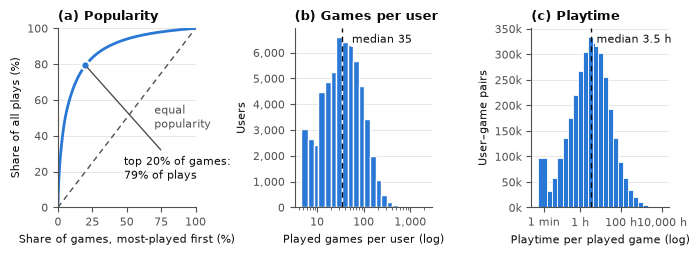

In [8]:
from matplotlib.ticker import FuncFormatter

INK, MUTED, GRID, BLUE, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6", "#fcfcfb"
plt.rcParams.update({"font.size": 8, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED})


def tidy(ax, title):
    ax.grid(axis="y", color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_title(title, loc="left", fontsize=9, color=INK, fontweight="bold")


def log_hist(ax, values, bins_per_decade=8, lw=1):
    """Histogram on a log axis with bin edges between whole numbers (the values are counts and minutes)."""
    lo, hi = np.log10(values.min()), np.log10(values.max())
    edges = np.unique(np.round(10 ** np.linspace(lo, hi, int((hi - lo) * bins_per_decade) + 2))) - 0.5
    if edges[-1] <= values.max():
        edges = np.append(edges, values.max() + 0.5)
    ax.hist(values, bins=edges, color=BLUE, edgecolor=SURFACE, lw=lw)
    ax.set_xscale("log")


fig, (a, b, c) = plt.subplots(1, 3, figsize=(7.0, 2.6))

head_x, head_y = evaluate.HEAD_SHARE * 100, head_plays * 100
a.plot([0, 100], [0, 100], color=MUTED, lw=1, ls=(0, (4, 3)))
a.plot(np.arange(players.size + 1) / players.size * 100,
       np.concatenate([[0], np.cumsum(players) / players.sum() * 100]), color=BLUE, lw=2)
a.plot([head_x], [head_y], "o", color=BLUE, ms=6, mec=SURFACE, mew=1.5)
a.annotate(f"top {head_x:.0f}% of games:\n{head_y:.0f}% of plays", xy=(head_x, head_y), xytext=(48, 16),
           color=INK, arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
a.text(70, 58, "equal\npopularity", color=MUTED, ha="left", va="top")
a.set_xlim(0, 100)
a.set_ylim(0, 100)
a.set_xlabel("Share of games, most-played first (%)")
a.set_ylabel("Share of all plays (%)")
tidy(a, "(a) Popularity")

log_hist(b, games_per_user)
med_b = np.median(games_per_user)
b.axvline(med_b, color=INK, lw=1, ls=(0, (4, 3)))
b.text(med_b * 1.6, b.get_ylim()[1] * 0.97, f"median {med_b:.0f}", color=INK, va="top",
       bbox=dict(fc="white", ec="none", pad=1))
b.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
b.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
b.set_xlabel("Played games per user (log)")
b.set_ylabel("Users")
tidy(b, "(b) Games per user")

log_hist(c, minutes, bins_per_decade=4, lw=0.6)
med_c = np.median(minutes)
c.axvline(med_c, color=INK, lw=1, ls=(0, (4, 3)))
c.text(med_c * 1.8, c.get_ylim()[1] * 0.97, f"median {med_c / 60:.1f} h", color=INK, va="top",
       bbox=dict(fc="white", ec="none", pad=1))
c.set_xticks([1, 60, 6_000, 600_000], ["1 min", "1 h", "100 h", "10,000 h"])
c.minorticks_off()
c.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
c.set_xlabel("Playtime per played game (log)")
c.set_ylabel("User–game pairs")
tidy(c, "(c) Playtime")

fig.tight_layout(w_pad=1.5)
fig.savefig(FIGURES / "data_overview.pdf")
fig.savefig(FIGURES / "data_overview.png", dpi=200)
plt.show()